In [128]:
# TF-IDF Book Recommendation Analysis

# ## Research Question
# How effectively can TF-IDF-based text similarity drive book recommendations, and does using bigrams improve recommendation quality over unigrams?
# This project analyzes 12 Project Gutenberg books across four assigned genres: mystery/detective, horror/gothic, adventure, and science fiction. TF-IDF is used to identify important terms, cosine similarity is used to compare books, and recommendation quality is evaluated using the assigned genres.

## 1. Setup and Data Loading

In [2]:
# imports

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# book files

book_folder = "books"

book_files = [
    file for file in os.listdir(book_folder)
    if file.endswith(".txt")
]

print("Number of books:", len(book_files))
print(book_files)

Number of books: 12
['TheAdventuresofSherlockHolmes.txt', 'TheMurderofRogerAckroyd.txt', 'PeterPan.txt', 'TheMisplacedBattleship.txt', 'TheMan.txt', 'TheTimeMachine.txt', 'Dracula.txt', "Alice'sAdventuresinWonderland.txt", 'TreasureIsland.txt', 'TheYellowWallpaper.txt', 'TheStrangeCaseofDr.JekyllandMr.Hyde.txt', 'TheMartian.txt']


In [4]:
# load books

books = {}

for file in book_files:
    file_path = os.path.join(book_folder, file)
    
    with open(file_path, "r", encoding="utf-8") as f:
        books[file] = f.read()

print("Books loaded:", len(books))

Books loaded: 12


In [5]:
## 2. Text Cleaning

# removing Gutenberg header and footer

def remove_gutenberg_info(text):
    
    start_match = re.search(
        r"\*\*\*\s*START OF.*?\*\*\*",
        text,
        flags=re.IGNORECASE
    )
    if start_match:
        text = text[start_match.end():]
    
    end_match = re.search(
        r"\*\*\*\s*END OF.*?\*\*\*",
        text,
        flags=re.IGNORECASE
    )
    if end_match:
        text = text[:end_match.start()]
    
    return text

In [6]:
# clean and tokenize text

def clean_text(text):
    
    # Remove Gutenberg header + footer
    text = remove_gutenberg_info(text)
    
    # lowercase
    text = text.lower()

    # remove apostrophes without creating separate letters
    text = re.sub(r"['’]", "", text)
    
    # remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # replacing multiple spaces + newlines with one space
    text = re.sub(r"\s+", " ", text)
    
    # text to list
    tokens = text.split()
    
    return tokens

In [7]:
# clean all books

cleaned_books = {}

for title, text in books.items():
    cleaned_books[title] = clean_text(text)

In [8]:
# remove stopwords

stopwords = {
    "a", "an", "the", "and", "or", "but", "if", "because", "as",
    "of", "at", "by", "for", "with", "about", "against", "between",
    "into", "through", "during", "before", "after", "above", "below",
    "to", "from", "up", "down", "in", "out", "on", "off", "over",
    "under", "again", "further", "then", "once",
    "is", "am", "are", "was", "were", "be", "been", "being",
    "have", "has", "had", "having", "do", "does", "did", "doing",
    "i", "me", "my", "myself", "we", "our", "ours", "ourselves",
    "you", "your", "yours", "yourself", "yourselves",
    "he", "him", "his", "himself", "she", "her", "hers",
    "herself", "it", "its", "itself", "they", "them", "their",
    "theirs", "themselves", "this", "that", "these", "those",
    "who", "whom", "which", "what",
    "not", "no", "nor", "so", "too", "very",
    "can", "will", "just", "should", "now", "all", "there", "one", "when",
    "would", "could", "some", "more", "us", "must",
    "only", "any", "how", "than", "upon", "such"
}

for title in cleaned_books:
    cleaned_books[title] = [
        word for word in cleaned_books[title]
        if word not in stopwords
    ]

In [9]:
## 3. Word Document Matrix

# create vocabulary

vocabulary = set()

for tokens in cleaned_books.values():
    vocabulary.update(tokens)
    
vocabulary = sorted(vocabulary)

print("Unique words:", len(vocabulary))

Unique words: 25107


In [10]:
# counting word occurrences in each book

word_counts = {}

for title, tokens in cleaned_books.items():
    counts = {}

    for word in tokens:
        counts[word] = counts.get(word, 0) + 1

    word_counts[title] = counts

In [11]:
# Word document table

word_document_df = pd.DataFrame(
    {
        title: [word_counts[title].get(word, 0) for word in vocabulary]
        for title in cleaned_books
    },
    index=vocabulary
)

print("Number of unique words:", word_document_df.shape[0])
print("Number of books:", word_document_df.shape[1])
word_document_df.head()

Number of unique words: 25107
Number of books: 12


,TheAdventuresofSherlockHolmes.txt,TheMurderofRogerAckroyd.txt,PeterPan.txt,TheMisplacedBattleship.txt,TheMan.txt,TheTimeMachine.txt,Dracula.txt,Alice'sAdventuresinWonderland.txt,TreasureIsland.txt,TheYellowWallpaper.txt,TheStrangeCaseofDr.JekyllandMr.Hyde.txt,TheMartian.txt
aback,0,8,1,0,2,0,1,0,3,0,0,0
abaft,0,0,0,0,0,0,2,0,0,0,0,0
abandon,0,0,0,0,4,1,1,0,1,0,0,0
abandoned,3,1,3,0,6,1,2,0,2,0,0,0
abandoning,0,1,1,0,0,0,0,0,0,0,0,0


In [12]:
# most common words across all books (added more stopwords after running)

total_word_counts = word_document_df.sum(axis=1)
total_word_counts.sort_values(ascending=False).head(20)

said      3809
little    1709
time      1690
see       1593
man       1591
know      1544
like      1502
well      1387
came      1310
good      1286
come      1200
back      1141
went      1141
way       1111
may       1063
think     1049
here      1044
made      1024
even      1024
much      1013
dtype: int64

In [13]:
## 4. Term Frequency (TF)

tf_df = word_document_df.copy().astype(float)

for title in tf_df.columns:
    total_words = word_document_df[title].sum()
    tf_df[title] = word_document_df[title] / total_words

tf_df.head()

,TheAdventuresofSherlockHolmes.txt,TheMurderofRogerAckroyd.txt,PeterPan.txt,TheMisplacedBattleship.txt,TheMan.txt,TheTimeMachine.txt,Dracula.txt,Alice'sAdventuresinWonderland.txt,TreasureIsland.txt,TheYellowWallpaper.txt,TheStrangeCaseofDr.JekyllandMr.Hyde.txt,TheMartian.txt
aback,0.000000,0.000231,0.000046,0.0,0.000042,0.000000,0.000014,0.0,0.000091,0.0,0.0,0.0
abaft,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000028,0.0,0.000000,0.0,0.0,0.0
abandon,0.000000,0.000000,0.000000,0.0,0.000084,0.000064,0.000014,0.0,0.000030,0.0,0.0,0.0
abandoned,0.000064,0.000029,0.000137,0.0,0.000127,0.000064,0.000028,0.0,0.000061,0.0,0.0,0.0
abandoning,0.000000,0.000029,0.000046,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0


In [14]:
# top TF terms for each book

for title in tf_df.columns:
    print(f"\n{title}")
    print(tf_df[title].sort_values(ascending=False).head(10))


TheAdventuresofSherlockHolmes.txt
said      0.010433
holmes    0.009918
man       0.006247
mr        0.005903
little    0.005775
see       0.004916
well      0.004358
may       0.004229
think     0.003735
room      0.003671
Name: TheAdventuresofSherlockHolmes.txt, dtype: float64

TheMurderofRogerAckroyd.txt
said        0.023187
poirot      0.012779
ackroyd     0.009916
know        0.006678
caroline    0.006071
ralph       0.005464
mr          0.005406
see         0.005146
man         0.005146
miss        0.005088
Name: TheMurderofRogerAckroyd.txt, dtype: float64

PeterPan.txt
peter      0.017204
said       0.016381
wendy      0.015191
hook       0.007001
cried      0.006223
john       0.005811
time       0.005765
darling    0.005079
see        0.004942
little     0.004759
Name: PeterPan.txt, dtype: float64

TheMisplacedBattleship.txt
ship          0.008734
battleship    0.007805
time          0.006876
said          0.006690
like          0.005203
way           0.004832
back          0

In [15]:
# doc frequency for each word

document_frequency = (word_document_df > 0).sum(axis=1)
document_frequency.head()

aback         5
abaft         1
abandon       4
abandoned     7
abandoning    2
dtype: int64

In [16]:
## 5. Inverse Document Frequency

num_documents = word_document_df.shape[1]

idf = np.log(
    num_documents / (1 + document_frequency)
)

# highest
idf.sort_values(ascending=False).head(20)

lares           1.791759
millaiss        1.791759
mightiest       1.791759
mightily        1.791759
mightst         1.791759
mignon          1.791759
migr            1.791759
migrated        1.791759
mike            1.791759
milan           1.791759
mildest         1.791759
milestone       1.791759
militaristic    1.791759
militating      1.791759
milkman         1.791759
millais         1.791759
millar          1.791759
mingoes         1.791759
milldam         1.791759
mille           1.791759
dtype: float64

In [17]:
# compare IDF of common terms

terms_to_check = [
    "said",
    "time",
    "man",
    "holmes",
    "poirot",
    "dracula",
    "alice",
    "machine"
]

for word in terms_to_check:
    if word in idf.index:
        print(
            f"{word}: documents = {document_frequency[word]}, "
            f"IDF = {idf[word]:.4f}"
        )

said: documents = 12, IDF = -0.0800
time: documents = 12, IDF = -0.0800
man: documents = 12, IDF = -0.0800
holmes: documents = 1, IDF = 1.7918
poirot: documents = 1, IDF = 1.7918
dracula: documents = 2, IDF = 1.3863
alice: documents = 3, IDF = 1.0986
machine: documents = 7, IDF = 0.4055


In [18]:
## 6. TF-IDF Analysis

tfidf_df = tf_df.mul(idf, axis=0)

# top terms by book
for title in tfidf_df.columns:
    print(f"\n{title}")
    print(tfidf_df[title].sort_values(ascending=False).head(10))


TheAdventuresofSherlockHolmes.txt
holmes      0.017770
sherlock    0.002887
watson      0.002410
lestrade    0.001423
rucastle    0.001308
mccarthy    0.001269
baker       0.001250
st          0.001220
simon       0.001161
coronet     0.001077
Name: TheAdventuresofSherlockHolmes.txt, dtype: float64

TheMurderofRogerAckroyd.txt
poirot       0.022896
ackroyd      0.017768
ralph        0.009790
caroline     0.008417
parker       0.007874
flora        0.005495
paton        0.005491
raymond      0.005387
inspector    0.004252
sheppard     0.003327
Name: TheMurderofRogerAckroyd.txt, dtype: float64

PeterPan.txt
wendy      0.027219
peter      0.015062
michael    0.006407
hook       0.006129
nana       0.004345
smee       0.004181
tink       0.004181
tootles    0.003689
darling    0.003520
nibs       0.003115
Name: PeterPan.txt, dtype: float64

TheMisplacedBattleship.txt
battleship    0.013985
pepe          0.007326
robot         0.006327
ferraro       0.003663
inskipp       0.003663
ship    

In [19]:
# compare TF and TF-IDF for one book

example_book = "TheAdventuresofSherlockHolmes.txt"

comparison = pd.DataFrame({
    "TF": tf_df[example_book],
    "TF-IDF": tfidf_df[example_book]
})

comparison.sort_values(
    "TF-IDF",
    ascending=False
).head(15)

,TF,TF-IDF
holmes,0.009918,0.017770
sherlock,0.002082,0.002887
watson,0.001739,0.002410
lestrade,0.000794,0.001423
rucastle,0.000730,0.001308
mccarthy,0.000708,0.001269
baker,0.000902,0.001250
st,0.001760,0.001220
simon,0.000837,0.001161
coronet,0.000601,0.001077


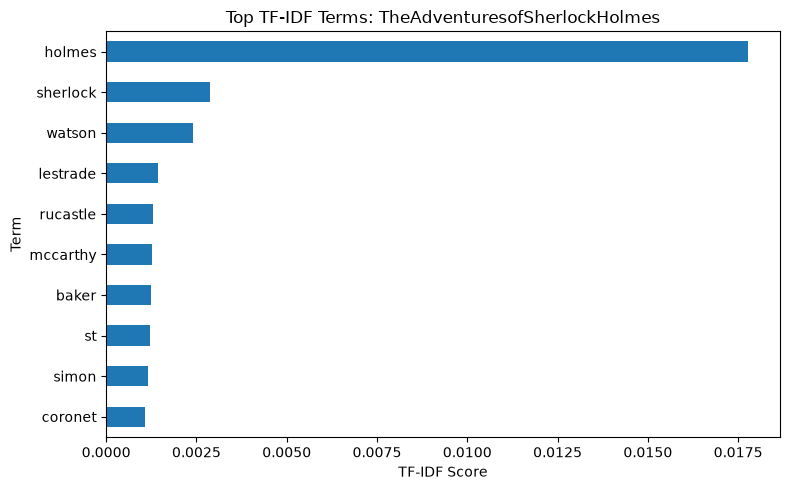

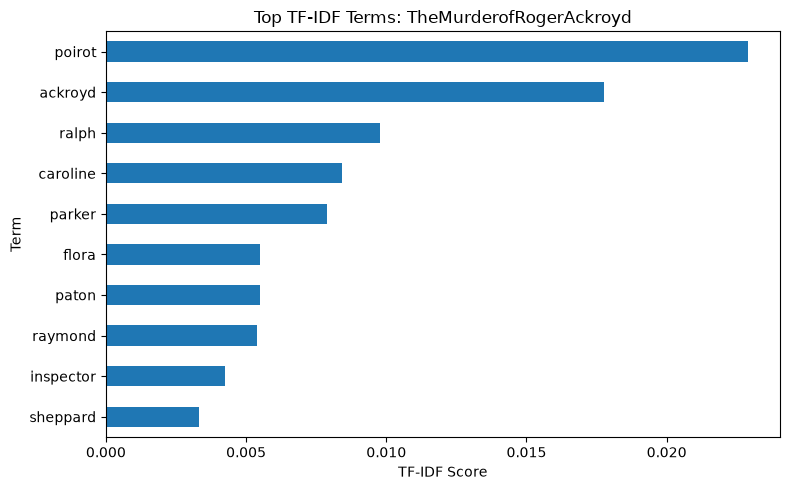

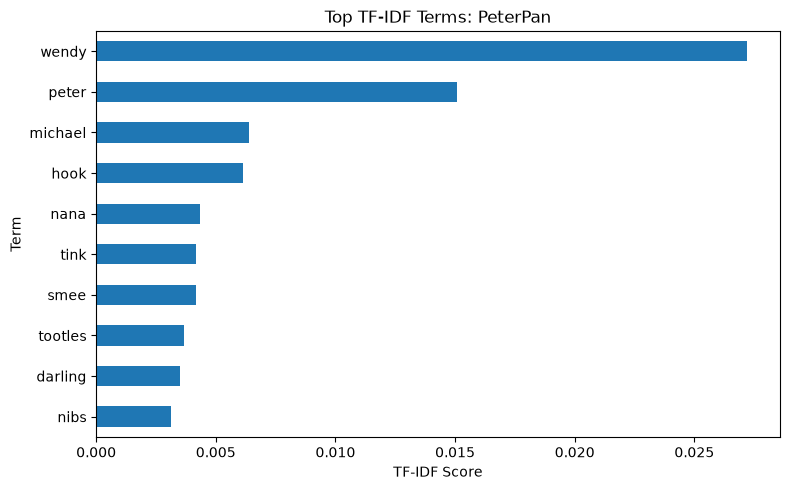

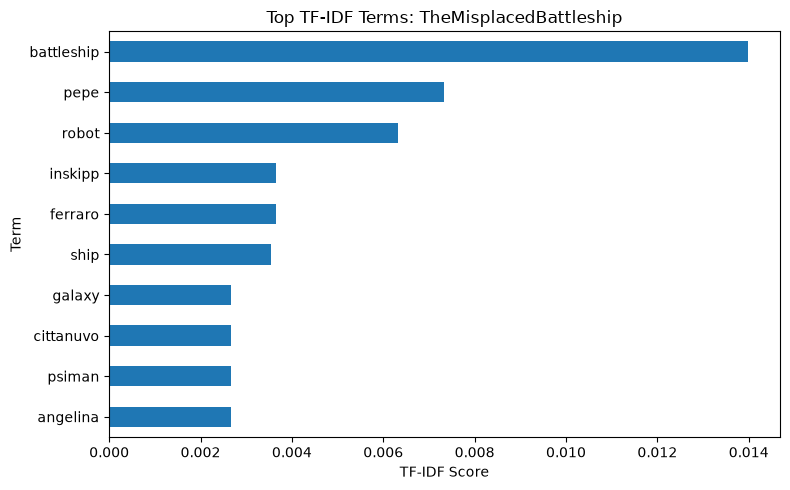

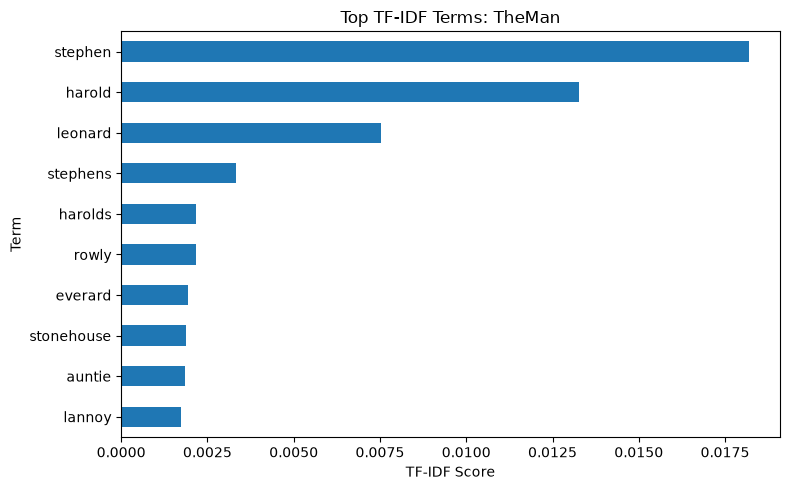

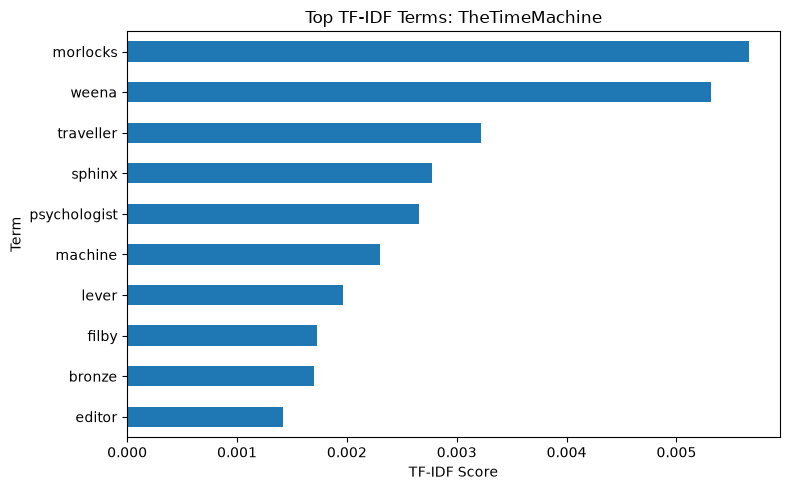

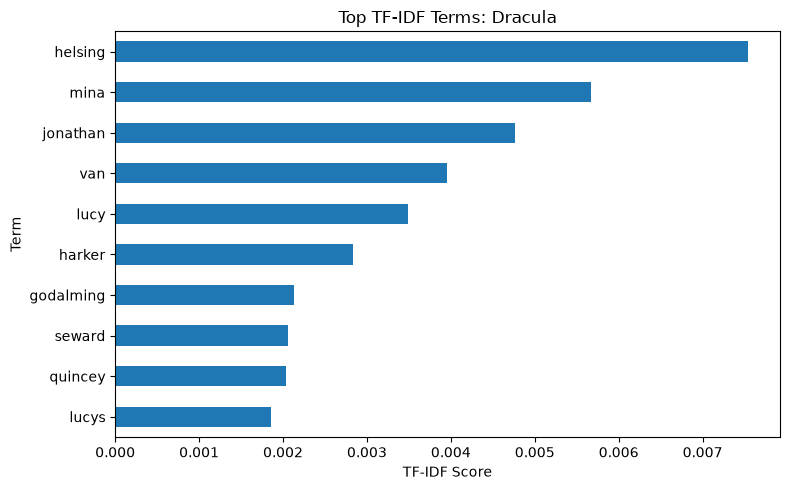

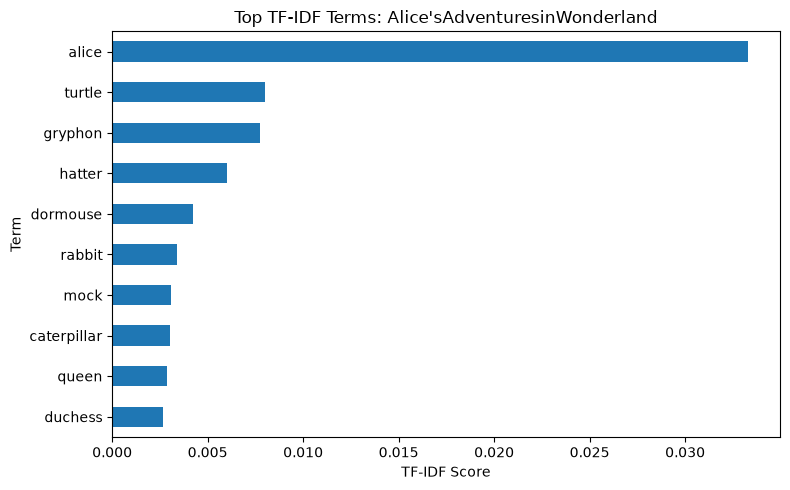

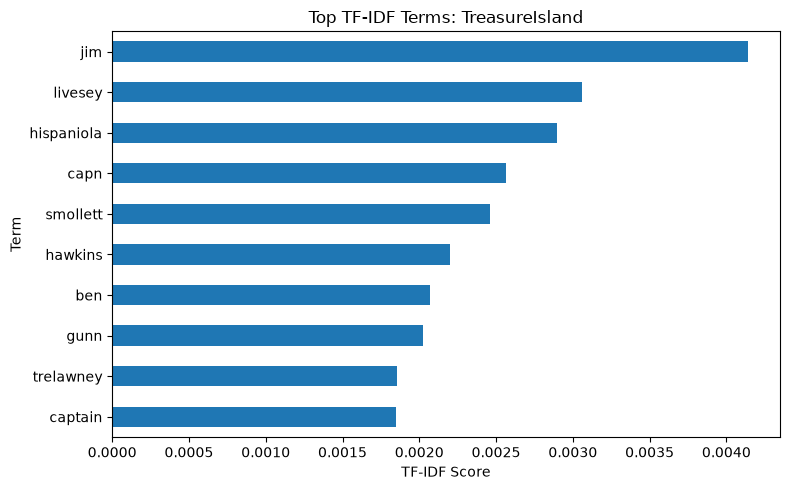

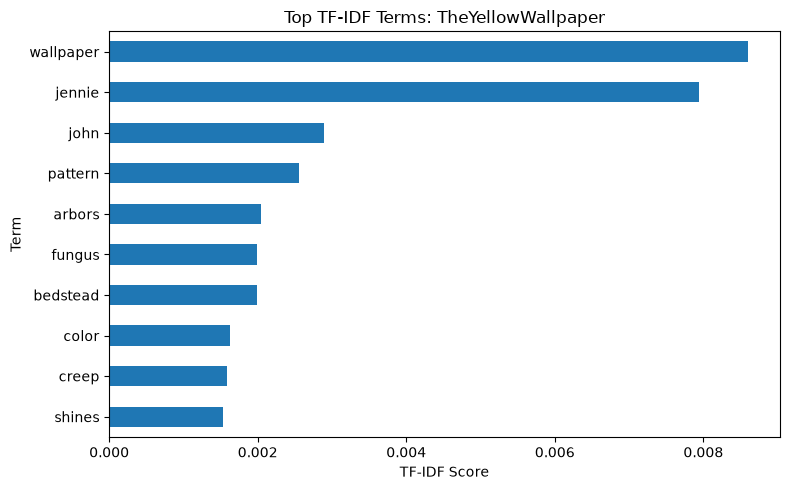

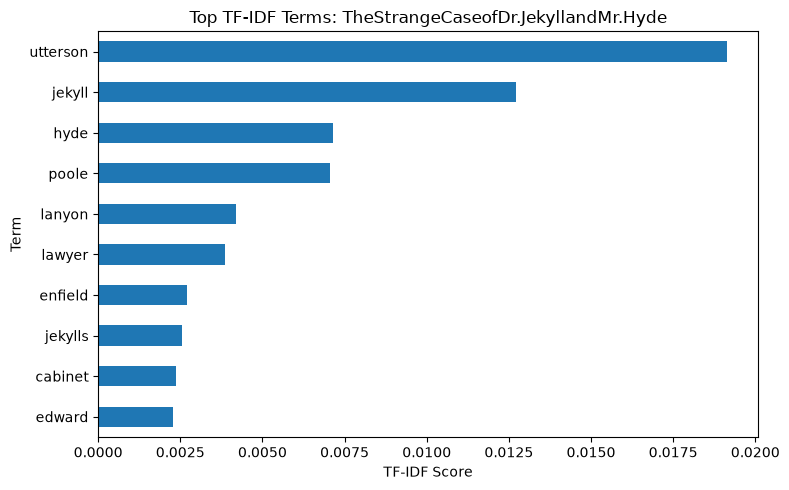

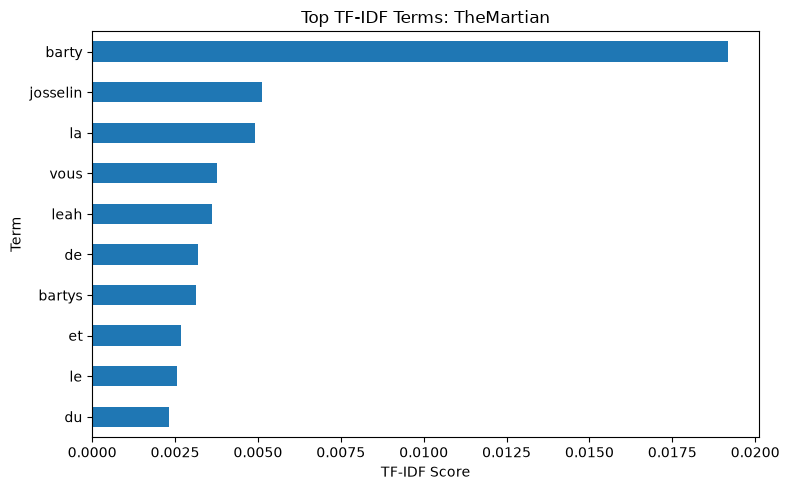

In [46]:
## 7. TF-IDF Visualization

# visualize top TF-IDF terms for each book

for title in tfidf_df.columns:
    
    top_terms = tfidf_df[title].sort_values(ascending=False).head(10)
    
    plt.figure(figsize=(8, 5))
    
    top_terms.sort_values().plot(kind="barh")
    
    plt.title(f"Top TF-IDF Terms: {title.replace('.txt', '')}")
    plt.xlabel("TF-IDF Score")
    plt.ylabel("Term")
    plt.tight_layout()
    plt.show()

In [21]:
## 8. Book Similarity and Recommendation System


def cosine_similarity(vector_a, vector_b):
    
    dot_product = np.dot(vector_a, vector_b)
    
    magnitude_a = np.linalg.norm(vector_a)
    magnitude_b = np.linalg.norm(vector_b)
    
    if magnitude_a == 0 or magnitude_b == 0:
        return 0
    
    return dot_product / (magnitude_a * magnitude_b)

In [22]:
# calculate similarity between every books

book_titles = list(tfidf_df.columns)

similarity_df = pd.DataFrame(
    index=book_titles,
    columns=book_titles,
    dtype=float
)

for book_a in book_titles:
    for book_b in book_titles:
        
        vector_a = tfidf_df[book_a].values
        vector_b = tfidf_df[book_b].values
        
        similarity_df.loc[book_a, book_b] = cosine_similarity(
            vector_a,
            vector_b
        )

similarity_df

,TheAdventuresofSherlockHolmes.txt,TheMurderofRogerAckroyd.txt,PeterPan.txt,TheMisplacedBattleship.txt,TheMan.txt,TheTimeMachine.txt,Dracula.txt,Alice'sAdventuresinWonderland.txt,TreasureIsland.txt,TheYellowWallpaper.txt,TheStrangeCaseofDr.JekyllandMr.Hyde.txt,TheMartian.txt
TheAdventuresofSherlockHolmes.txt,1.000000,0.025684,0.014167,0.020911,0.021892,0.035693,0.042162,0.025936,0.039387,0.026914,0.022716,0.022732
TheMurderofRogerAckroyd.txt,0.025684,1.000000,0.008998,0.010765,0.011778,0.015900,0.021052,0.010424,0.022901,0.015609,0.012895,0.025157
PeterPan.txt,0.014167,0.008998,1.000000,0.012016,0.012866,0.017554,0.022790,0.010125,0.036241,0.026006,0.009017,0.013663
TheMisplacedBattleship.txt,0.020911,0.010765,0.012016,1.000000,0.013128,0.027028,0.024054,0.008322,0.053640,0.018502,0.009689,0.011759
TheMan.txt,0.021892,0.011778,0.012866,0.013128,1.000000,0.027082,0.038252,0.010383,0.033777,0.019010,0.013448,0.018879
TheTimeMachine.txt,0.035693,0.015900,0.017554,0.027028,0.027082,1.000000,0.045232,0.016230,0.054377,0.035119,0.027443,0.024419
Dracula.txt,0.042162,0.021052,0.022790,0.024054,0.038252,0.045232,1.000000,0.016858,0.065507,0.038039,0.027456,0.027012
Alice'sAdventuresinWonderland.txt,0.025936,0.010424,0.010125,0.008322,0.010383,0.016230,0.016858,1.000000,0.022089,0.016261,0.008119,0.010181
TreasureIsland.txt,0.039387,0.022901,0.036241,0.053640,0.033777,0.054377,0.065507,0.022089,1.000000,0.042934,0.028593,0.026127
TheYellowWallpaper.txt,0.026914,0.015609,0.026006,0.018502,0.019010,0.035119,0.038039,0.016261,0.042934,1.000000,0.018369,0.020147


In [23]:
# ordering similarity

similar_pairs = []

for i in range(len(book_titles)):
    for j in range(i + 1, len(book_titles)):
        
        book_a = book_titles[i]
        book_b = book_titles[j]
        
        similar_pairs.append(
            (
                book_a,
                book_b,
                similarity_df.loc[book_a, book_b]
            )
        )

similar_pairs = sorted(
    similar_pairs,
    key=lambda x: x[2],
    reverse=True
)

for book_a, book_b, score in similar_pairs[:10]:
    print(
        f"{book_a} <-> {book_b}: {score:.4f}"
    )

Dracula.txt <-> TreasureIsland.txt: 0.0655
TheTimeMachine.txt <-> TreasureIsland.txt: 0.0544
TheMisplacedBattleship.txt <-> TreasureIsland.txt: 0.0536
TheTimeMachine.txt <-> Dracula.txt: 0.0452
TreasureIsland.txt <-> TheYellowWallpaper.txt: 0.0429
TheAdventuresofSherlockHolmes.txt <-> Dracula.txt: 0.0422
TheAdventuresofSherlockHolmes.txt <-> TreasureIsland.txt: 0.0394
TheMan.txt <-> Dracula.txt: 0.0383
Dracula.txt <-> TheYellowWallpaper.txt: 0.0380
PeterPan.txt <-> TreasureIsland.txt: 0.0362


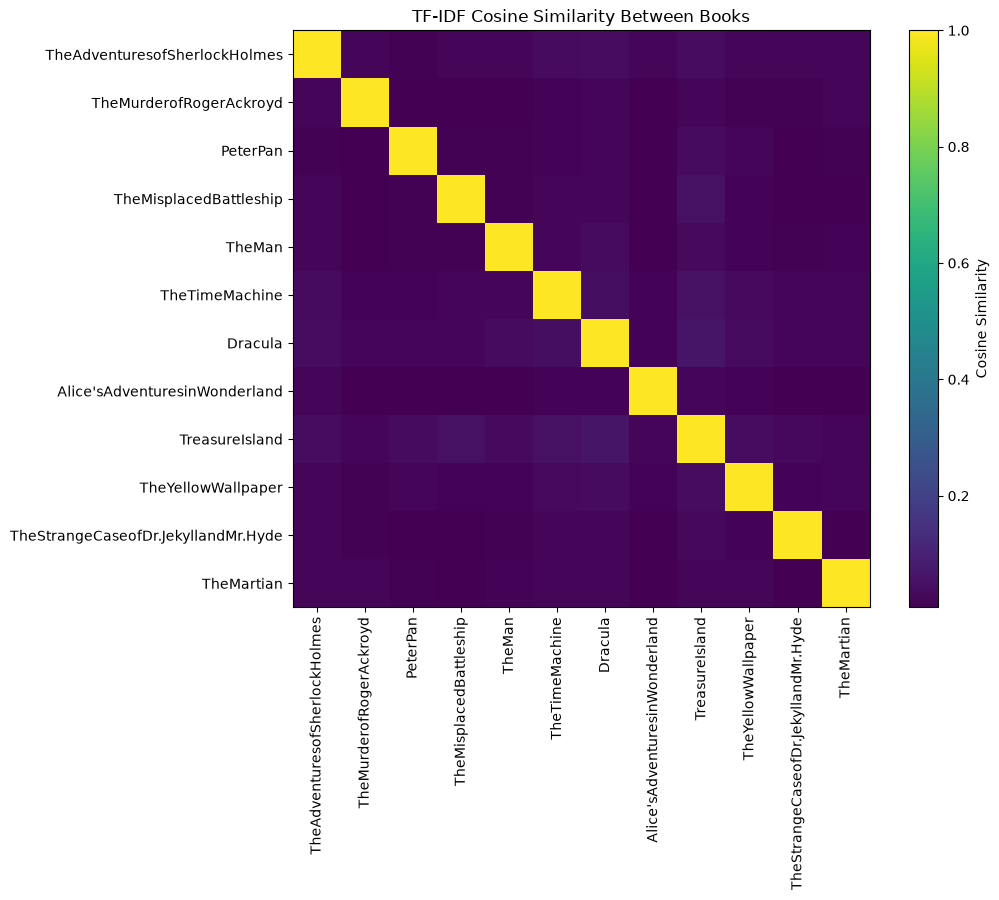

In [24]:
# visualize book similarity matrix

short_names = [
    title.replace(".txt", "")
    for title in similarity_df.columns
]

plt.figure(figsize=(11, 9))
plt.imshow(similarity_df.values)
plt.colorbar(label="Cosine Similarity")
plt.xticks(
    range(len(short_names)),
    short_names,
    rotation=90
)
plt.yticks(
    range(len(short_names)),
    short_names
)
plt.title("TF-IDF Cosine Similarity Between Books")
plt.tight_layout()
plt.show()

In [25]:
# recommend similar books

def recommend_books(book, n=3):
    
    similarities = similarity_df[book].drop(book)
    
    recommendations = similarities.sort_values(
        ascending=False
    ).head(n)
    
    return recommendations

# test
recommend_books("Dracula.txt")

TreasureIsland.txt                   0.065507
TheTimeMachine.txt                   0.045232
TheAdventuresofSherlockHolmes.txt    0.042162
Name: Dracula.txt, dtype: float64

In [26]:
## 9. Bigram TF-IDF Experiment

# create bigrams for each book

def create_bigrams(tokens):
    return [
        tokens[i] + " " + tokens[i + 1]
        for i in range(len(tokens) - 1)
    ]

bigram_books = {}

for title, tokens in cleaned_books.items():
    bigram_books[title] = create_bigrams(tokens)

In [27]:
# bigram vocabulary

bigram_vocabulary = set()

for bigrams in bigram_books.values():
    bigram_vocabulary.update(bigrams)

bigram_vocabulary = sorted(bigram_vocabulary)

print("Total unique bigrams:", len(bigram_vocabulary))

Total unique bigrams: 289930


In [28]:
# count bigram occurrences

bigram_counts = {}

for title, bigrams in bigram_books.items():
    
    counts = {}
    
    for bigram in bigrams:
        counts[bigram] = counts.get(bigram, 0) + 1
    
    bigram_counts[title] = counts

In [29]:
# bigram-document table

bigram_document_df = pd.DataFrame(
    {
        title: [
            bigram_counts[title].get(bigram, 0)
            for bigram in bigram_vocabulary
        ]
        for title in bigram_books
    },
    index=bigram_vocabulary
)

print("Unique bigrams:", bigram_document_df.shape[0])
print("Books:", bigram_document_df.shape[1])

Unique bigrams: 289930
Books: 12


In [30]:
# calculate bigram TF

bigram_tf_df = bigram_document_df.copy().astype(float)

for title in bigram_tf_df.columns:
    
    total_bigrams = bigram_document_df[title].sum()
    
    bigram_tf_df[title] = (
        bigram_document_df[title] / total_bigrams
    )

In [31]:
# calculate bigram IDF

bigram_document_frequency = (
    bigram_document_df > 0
).sum(axis=1)

num_documents = bigram_document_df.shape[1]

bigram_idf = np.log(
    num_documents /
    (1 + bigram_document_frequency)
)

In [32]:
# calculate bigram TF-IDF

bigram_tfidf_df = bigram_tf_df.mul(
    bigram_idf,
    axis=0
)

In [33]:
# top bigram TF-IDF terms

for title in bigram_tfidf_df.columns:
    
    print(f"\n{title}")
    
    print(
        bigram_tfidf_df[title]
        .sort_values(ascending=False)
        .head(10)
    )


TheAdventuresofSherlockHolmes.txt
said holmes        0.004308
sherlock holmes    0.003731
mr holmes          0.002731
st simon           0.001500
baker street       0.001115
lord st            0.001077
miss hunter        0.000692
st clair           0.000684
hosmer angel       0.000654
mr rucastle        0.000654
Name: TheAdventuresofSherlockHolmes.txt, dtype: float64

TheMurderofRogerAckroyd.txt
mr ackroyd       0.005595
said poirot      0.004766
mrs ackroyd      0.004351
ralph paton      0.003937
m poirot         0.003574
said caroline    0.003471
dr sheppard      0.003212
miss russell     0.002901
miss ganett      0.002487
major blunt      0.002072
Name: TheMurderofRogerAckroyd.txt, dtype: float64

PeterPan.txt
mrs darling     0.005329
mr darling      0.003198
wendy said      0.002542
tinker bell     0.002296
john michael    0.002214
peter said      0.001968
said peter      0.001804
peter pan       0.001476
make believe    0.000984
said wendy      0.000984
Name: PeterPan.txt, dtype:

In [34]:
# bigram cosine similarities

bigram_similarity_df = pd.DataFrame(
    index=book_titles,
    columns=book_titles,
    dtype=float
)

for book_a in book_titles:
    for book_b in book_titles:
        
        vector_a = bigram_tfidf_df[book_a].values
        vector_b = bigram_tfidf_df[book_b].values
        
        bigram_similarity_df.loc[book_a, book_b] = (
            cosine_similarity(vector_a, vector_b)
        )

bigram_similarity_df

,TheAdventuresofSherlockHolmes.txt,TheMurderofRogerAckroyd.txt,PeterPan.txt,TheMisplacedBattleship.txt,TheMan.txt,TheTimeMachine.txt,Dracula.txt,Alice'sAdventuresinWonderland.txt,TreasureIsland.txt,TheYellowWallpaper.txt,TheStrangeCaseofDr.JekyllandMr.Hyde.txt,TheMartian.txt
TheAdventuresofSherlockHolmes.txt,1.000000,0.016017,0.008590,0.003815,0.019259,0.007814,0.018022,0.006139,0.012934,0.004052,0.008510,0.015541
TheMurderofRogerAckroyd.txt,0.016017,1.000000,0.006365,0.004044,0.014222,0.004868,0.011405,0.007645,0.008892,0.004087,0.005819,0.010983
PeterPan.txt,0.008590,0.006365,1.000000,0.002722,0.012935,0.004716,0.009349,0.006573,0.012533,0.005518,0.003740,0.009293
TheMisplacedBattleship.txt,0.003815,0.004044,0.002722,1.000000,0.005813,0.002924,0.004647,0.002221,0.004714,0.001605,0.001670,0.004143
TheMan.txt,0.019259,0.014222,0.012935,0.005813,1.000000,0.009460,0.033061,0.008492,0.015711,0.006294,0.008480,0.019808
TheTimeMachine.txt,0.007814,0.004868,0.004716,0.002924,0.009460,1.000000,0.008504,0.003900,0.007863,0.002225,0.003204,0.007718
Dracula.txt,0.018022,0.011405,0.009349,0.004647,0.033061,0.008504,1.000000,0.006649,0.012994,0.005778,0.006964,0.014578
Alice'sAdventuresinWonderland.txt,0.006139,0.007645,0.006573,0.002221,0.008492,0.003900,0.006649,1.000000,0.007018,0.003232,0.002694,0.007269
TreasureIsland.txt,0.012934,0.008892,0.012533,0.004714,0.015711,0.007863,0.012994,0.007018,1.000000,0.004178,0.009773,0.011949
TheYellowWallpaper.txt,0.004052,0.004087,0.005518,0.001605,0.006294,0.002225,0.005778,0.003232,0.004178,1.000000,0.001592,0.005282


In [35]:
# most similar bigram pairs

bigram_pairs = []

for i in range(len(book_titles)):
    for j in range(i + 1, len(book_titles)):
        
        book_a = book_titles[i]
        book_b = book_titles[j]
        bigram_pairs.append(
            (
                book_a,
                book_b,
                bigram_similarity_df.loc[book_a, book_b]
            )
        )

bigram_pairs = sorted(
    bigram_pairs,
    key=lambda x: x[2],
    reverse=True
)

for book_a, book_b, score in bigram_pairs[:10]:
    print(f"{book_a} <-> {book_b}: {score:.4f}")

TheMan.txt <-> Dracula.txt: 0.0331
TheMan.txt <-> TheMartian.txt: 0.0198
TheAdventuresofSherlockHolmes.txt <-> TheMan.txt: 0.0193
TheAdventuresofSherlockHolmes.txt <-> Dracula.txt: 0.0180
TheAdventuresofSherlockHolmes.txt <-> TheMurderofRogerAckroyd.txt: 0.0160
TheMan.txt <-> TreasureIsland.txt: 0.0157
TheAdventuresofSherlockHolmes.txt <-> TheMartian.txt: 0.0155
Dracula.txt <-> TheMartian.txt: 0.0146
TheMurderofRogerAckroyd.txt <-> TheMan.txt: 0.0142
Dracula.txt <-> TreasureIsland.txt: 0.0130


In [36]:
## 10. Unigram vs. Bigram Recommendations

def compare_recommendations(book, n=3):
    
    unigram = (
        similarity_df[book]
        .drop(book)
        .sort_values(ascending=False)
        .head(n)
    )
    bigram = (
        bigram_similarity_df[book]
        .drop(book)
        .sort_values(ascending=False)
        .head(n)
    )
    
    comparison = pd.DataFrame({
        "Unigram Recommendation": unigram.index,
        "Unigram Similarity": unigram.values,
        "Bigram Recommendation": bigram.index,
        "Bigram Similarity": bigram.values
    })
    
    return comparison

In [37]:
# compare recommendations across 4 selected genres

test_books = [
    "TheAdventuresofSherlockHolmes.txt",
    "Dracula.txt",
    "TreasureIsland.txt",
    "TheTimeMachine.txt"
]

for book in test_books:
    print(f"\n{book}")
    display(compare_recommendations(book))


TheAdventuresofSherlockHolmes.txt


,Unigram Recommendation,Unigram Similarity,Bigram Recommendation,Bigram Similarity
0,Dracula.txt,0.042162,TheMan.txt,0.019259
1,TreasureIsland.txt,0.039387,Dracula.txt,0.018022
2,TheTimeMachine.txt,0.035693,TheMurderofRogerAckroyd.txt,0.016017



Dracula.txt


,Unigram Recommendation,Unigram Similarity,Bigram Recommendation,Bigram Similarity
0,TreasureIsland.txt,0.065507,TheMan.txt,0.033061
1,TheTimeMachine.txt,0.045232,TheAdventuresofSherlockHolmes.txt,0.018022
2,TheAdventuresofSherlockHolmes.txt,0.042162,TheMartian.txt,0.014578



TreasureIsland.txt


,Unigram Recommendation,Unigram Similarity,Bigram Recommendation,Bigram Similarity
0,Dracula.txt,0.065507,TheMan.txt,0.015711
1,TheTimeMachine.txt,0.054377,Dracula.txt,0.012994
2,TheMisplacedBattleship.txt,0.053640,TheAdventuresofSherlockHolmes.txt,0.012934



TheTimeMachine.txt


,Unigram Recommendation,Unigram Similarity,Bigram Recommendation,Bigram Similarity
0,TreasureIsland.txt,0.054377,TheMan.txt,0.009460
1,Dracula.txt,0.045232,Dracula.txt,0.008504
2,TheAdventuresofSherlockHolmes.txt,0.035693,TreasureIsland.txt,0.007863


In [38]:
## 11. Recommendation Evaluation

book_genres = {
    "TheAdventuresofSherlockHolmes.txt": "Mystery",
    "TheMurderofRogerAckroyd.txt": "Mystery",
    "TheStrangeCaseofDr.JekyllandMr.Hyde.txt": "Mystery",

    "Dracula.txt": "Horror",
    "TheMan.txt": "Horror",
    "TheYellowWallpaper.txt": "Horror",

    "TreasureIsland.txt": "Adventure",
    "PeterPan.txt": "Adventure",
    "Alice'sAdventuresinWonderland.txt": "Adventure",

    "TheTimeMachine.txt": "Science Fiction",
    "TheMartian.txt": "Science Fiction",
    "TheMisplacedBattleship.txt": "Science Fiction"
}

In [39]:
# evaluate recommendation accuracy

def evaluate_recommendations(similarity_matrix, n=3):
    
    correct = 0
    total = 0
    for book in similarity_matrix.columns:
        
        recommendations = (
            similarity_matrix[book]
            .drop(book)
            .sort_values(ascending=False)
            .head(n)
        )
    
        for recommended_book in recommendations.index:
            if book_genres[book] == book_genres[recommended_book]:
                correct += 1
            total += 1
    
    return correct / total

In [40]:
# compare recommendation accuracy

unigram_accuracy = evaluate_recommendations(
    similarity_df
)

bigram_accuracy = evaluate_recommendations(
    bigram_similarity_df
)

In [41]:
# random recommendation baseline

random_baseline = 2 / 11

print(f"Random baseline: {random_baseline:.2%}")
print(f"Unigram TF-IDF: {unigram_accuracy:.2%}")
print(f"Bigram TF-IDF: {bigram_accuracy:.2%}")

Random baseline: 18.18%
Unigram TF-IDF: 16.67%
Bigram TF-IDF: 22.22%
